# Практическая работа №6
## Классификация текстовых данных с использованием TF-IDF

**Вариант:** уровень B

**Датасет:** SMS Spam Collection

**Задача:** классификация SMS-сообщений на обычные сообщения и спам.

In [1]:
from pathlib import Path
import zipfile

zip_path = Path("data/sms_spam_collection.zip")
extract_folder = Path("data")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Архив успешно распакован!")
print("Файлы:", list(extract_folder.iterdir()))

Архив успешно распакован!
Файлы: [WindowsPath('data/readme'), WindowsPath('data/SMSSpamCollection'), WindowsPath('data/sms_spam_collection.zip')]


In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Библиотеки успешно импортированы!")

Библиотеки успешно импортированы!


## 1. Загрузка и первичное изучение данных

In [4]:
candidates = [
    Path("data/SMSSpamCollection"),
    Path("Practical_6_Text_Classification/data/SMSSpamCollection")
]

DATA_PATH = next((p for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Файл SMSSpamCollection не найден. Проверь папку data."
    )

df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["label", "text"],
    encoding="utf-8"
)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64


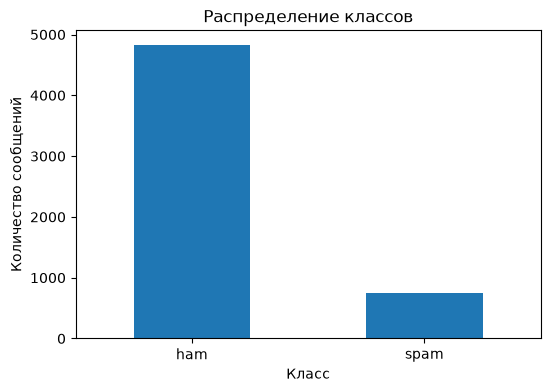

In [5]:
print(df["label"].value_counts())

df["label"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество сообщений")
plt.xticks(rotation=0)
plt.show()

## 2. Предобработка и очистка текста

In [6]:
# Стоп-слова английского языка
# Сохраняем no, not и nor, чтобы не терять отрицания

stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor"}


def clean_text(text):
    # 1. Приведение к нижнему регистру
    text = text.lower()

    # 2. Удаление цифр и пунктуации
    text = re.sub(r"[^a-z\s]", " ", text)

    # 3. Токенизация
    tokens = text.split()

    # 4. Удаление стоп-слов
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 5. Объединение слов обратно в строку
    return " ".join(tokens)


print("Функция очистки создана!")

Функция очистки создана!


In [7]:
examples = [
    "URGENT! You have WON 1000 pounds!!!",
    "I am NOT interested in this offer.",
    "Hello, how are you doing today?"
]

for message in examples:
    print("Исходный текст:", message)
    print("После очистки:", clean_text(message))
    print("-" * 50)

Исходный текст: URGENT! You have WON 1000 pounds!!!
После очистки: urgent won pounds
--------------------------------------------------
Исходный текст: I am NOT interested in this offer.
После очистки: not interested offer
--------------------------------------------------
Исходный текст: Hello, how are you doing today?
После очистки: hello doing today
--------------------------------------------------


In [8]:
df["clean_text"] = df["text"].apply(clean_text)

display(df[["text", "clean_text"]].head(10))

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c say
4,"Nah I don't think he goes to usf, he lives aro...",nah don t think goes usf lives
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling s week s no word d like fu...
6,Even my brother is not like to speak with me. ...,brother not like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,request melle melle oru minnaminunginte nurung...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...


## 3. Разделение данных на обучающую и тестовую выборки

In [10]:
X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (4457,)
Размер тестовой выборки: (1115,)


## 4. Векторизация текста с помощью TF-IDF

In [11]:
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=clean_text,
            lowercase=False,
            min_df=2,
            max_df=0.95,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


In [12]:
X_train_tfidf = model.named_steps["tfidf"].transform(X_train)
X_test_tfidf = model.named_steps["tfidf"].transform(X_test)

print("Размерность обучающей матрицы:", X_train_tfidf.shape)
print("Размерность тестовой матрицы:", X_test_tfidf.shape)

Размерность обучающей матрицы: (4457, 6885)
Размерность тестовой матрицы: (1115, 6885)


## 5. Оценка качества классификации

In [13]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="spam")
recall = recall_score(y_test, y_pred, pos_label="spam")
f1 = f1_score(y_test, y_pred, pos_label="spam")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

Accuracy: 0.9749
Precision: 0.9007
Recall: 0.9128
F1-score: 0.9067


In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       966
        spam       0.90      0.91      0.91       149

    accuracy                           0.97      1115
   macro avg       0.94      0.95      0.95      1115
weighted avg       0.98      0.97      0.97      1115



## 6. Матрица ошибок

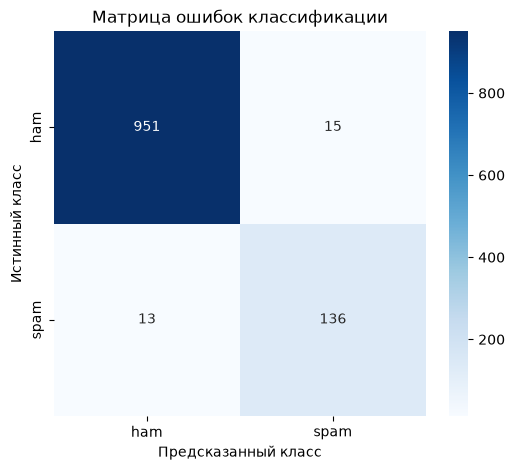

In [15]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.title("Матрица ошибок классификации")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

## 7. Анализ ошибок классификации

In [16]:
results = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "predicted_label": y_pred
})

errors = results[
    results["true_label"] != results["predicted_label"]
].copy()

print("Количество ошибок:", len(errors))

display(errors.head(5))

Количество ошибок: 28


,text,true_label,predicted_label
5,FreeMsg Hey there darling it's been 3 week's n...,spam,ham
670,Did u receive my msg?,ham,spam
1497,I'm always on yahoo messenger now. Just send t...,ham,spam
3750,Dear Voucher Holder 2 claim your 1st class air...,spam,ham
3981,ringtoneking 84484,spam,ham


In [17]:
display(errors.head(5).style.set_properties(
    **{"text-align": "left"}
))

,text,true_label,predicted_label
5,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv",spam,ham
670,Did u receive my msg?,ham,spam
1497,I'm always on yahoo messenger now. Just send the message to me and i.ll get it you may have to send it in the mobile mode sha but i.ll get it. And will reply.,ham,spam
3750,Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher call 08704439680. When booking quote 1st class x 2,spam,ham
3981,ringtoneking 84484,spam,ham


## 8. Итоговый вывод

В ходе практической работы был реализован самостоятельный пайплайн классификации текстовых данных.

Была выполнена очистка текста: приведение к нижнему регистру, удаление цифр и пунктуации, токенизация и удаление стоп-слов.

Для преобразования текстов в числовые признаки использовался метод TF-IDF с ограничением словаря через параметры min_df и max_df.

Для классификации была обучена модель Logistic Regression.

Качество модели оценивалось с помощью Accuracy, Precision, Recall и F1-score, а также матрицы ошибок.

Дополнительно были изучены пять ошибочно классифицированных сообщений и сформулированы гипотезы о причинах ошибок.

В результате был создан полный процесс обработки текста и его классификации без утечки данных при векторизации.